In [1]:
pip install numpy

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np


In [3]:
sample_customers = pd.DataFrame({
    "customer_id" : [101, 102, 103, 104, 105],
    "age" : [25, 31, 28, 45, 36],
    "city" : ["Kochi", "Kozhikode", "Thrissur", "Kochi", "Kollam"],
    "purchase_amount" : [1200, 2300, 1800, 5200, 3100]
})

In [4]:
print(sample_customers)

   customer_id  age       city  purchase_amount
0          101   25      Kochi             1200
1          102   31  Kozhikode             2300
2          103   28   Thrissur             1800
3          104   45      Kochi             5200
4          105   36     Kollam             3100


In [5]:
sample_customers.to_csv("sample_csv", index=False)

In [6]:
csv_df = pd.read_csv("sample_csv")

In [7]:
print(csv_df)

   customer_id  age       city  purchase_amount
0          101   25      Kochi             1200
1          102   31  Kozhikode             2300
2          103   28   Thrissur             1800
3          104   45      Kochi             5200
4          105   36     Kollam             3100


In [8]:
csv_df.head()

,customer_id,age,city,purchase_amount
0,101,25,Kochi,1200
1,102,31,Kozhikode,2300
2,103,28,Thrissur,1800
3,104,45,Kochi,5200
4,105,36,Kollam,3100


In [9]:
csv_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   customer_id      5 non-null      int64
 1   age              5 non-null      int64
 2   city             5 non-null      str  
 3   purchase_amount  5 non-null      int64
dtypes: int64(3), str(1)
memory usage: 292.0 bytes


In [10]:
csv_df.describe()

,customer_id,age,purchase_amount
count,5.000000,5.000000,5.000000
mean,103.000000,33.000000,2720.000000
std,1.581139,7.842194,1551.450934
min,101.000000,25.000000,1200.000000
25%,102.000000,28.000000,1800.000000
50%,103.000000,31.000000,2300.000000
75%,104.000000,36.000000,3100.000000
max,105.000000,45.000000,5200.000000


In [11]:
csv_df.describe(include = "all")

,customer_id,age,city,purchase_amount
count,5.000000,5.000000,5,5.000000
unique,NaN,NaN,4,NaN
top,NaN,NaN,Kochi,NaN
freq,NaN,NaN,2,NaN
mean,103.000000,33.000000,NaN,2720.000000
std,1.581139,7.842194,NaN,1551.450934
min,101.000000,25.000000,NaN,1200.000000
25%,102.000000,28.000000,NaN,1800.000000
50%,103.000000,31.000000,NaN,2300.000000
75%,104.000000,36.000000,NaN,3100.000000


In [12]:
csv_df.isna()

,customer_id,age,city,purchase_amount
0,False,False,False,False
1,False,False,False,False
2,False,False,False,False
3,False,False,False,False
4,False,False,False,False


In [13]:
csv_df.isna().sum()

customer_id        0
age                0
city               0
purchase_amount    0
dtype: int64

In [14]:
missing_demo = pd.DataFrame({
    "age" : [25, 31, np.nan, 42, 35, np.nan],
    "income" : [30000, 42000, 51000, np.nan, 65000, 72000],
    "city" : ["Kochi", "Kozhikode", "Kochi", None, "Kollam", "Kochi"]
})

In [15]:
print(missing_demo.isna().sum())
display(missing_demo.isna().sum())


age       2
income    1
city      1
dtype: int64


age       2
income    1
city      1
dtype: int64

In [16]:
print(missing_demo)
display(missing_demo)

    age   income       city
0  25.0  30000.0      Kochi
1  31.0  42000.0  Kozhikode
2   NaN  51000.0      Kochi
3  42.0      NaN        NaN
4  35.0  65000.0     Kollam
5   NaN  72000.0      Kochi


,age,income,city
0,25.0,30000.0,Kochi
1,31.0,42000.0,Kozhikode
2,NaN,51000.0,Kochi
3,42.0,NaN,NaN
4,35.0,65000.0,Kollam
5,NaN,72000.0,Kochi


In [17]:
missing_demo.dropna(inplace = True)

In [18]:
missing_demo.dropna()

,age,income,city
0,25.0,30000.0,Kochi
1,31.0,42000.0,Kozhikode
4,35.0,65000.0,Kollam


In [19]:
from sklearn.impute import SimpleImputer

mean_imputer = SimpleImputer(strategy = "mean")
csv_df["purchase_amount"] = mean_imputer.fit_transform(
    csv_df[["purchase_amount"]]
)

display(csv_df)

,customer_id,age,city,purchase_amount
0,101,25,Kochi,1200.0
1,102,31,Kozhikode,2300.0
2,103,28,Thrissur,1800.0
3,104,45,Kochi,5200.0
4,105,36,Kollam,3100.0


In [20]:
from sklearn.impute import SimpleImputer

median_imputer = SimpleImputer(strategy = "median")
missing_demo["income"] = median_imputer.fit_transform(
    missing_demo[["income"]]
)

display(missing_demo)

,age,income,city
0,25.0,30000.0,Kochi
1,31.0,42000.0,Kozhikode
4,35.0,65000.0,Kollam


In [21]:
from sklearn.impute import SimpleImputer

mode_imputer = SimpleImputer(strategy = "most_frequent")
missing_demo["income"] = mode_imputer.fit_transform(
    missing_demo[["income"]]
)

display(missing_demo)

,age,income,city
0,25.0,30000.0,Kochi
1,31.0,42000.0,Kozhikode
4,35.0,65000.0,Kollam


In [22]:
missing_demo["city"].fillna(missing_demo["city"].mode())

0        Kochi
1    Kozhikode
4       Kollam
Name: city, dtype: str

In [23]:
missing_demo["income"].fillna(missing_demo["income"].median())

0    30000.0
1    42000.0
4    65000.0
Name: income, dtype: float64

In [24]:
missing_demo["city"].mode()

0        Kochi
1       Kollam
2    Kozhikode
Name: city, dtype: str

In [25]:
missing_demo["city"].ffill()

0        Kochi
1    Kozhikode
4       Kollam
Name: city, dtype: str

In [26]:
missing_demo["city"].bfill()

0        Kochi
1    Kozhikode
4       Kollam
Name: city, dtype: str

In [27]:
csv_df.duplicated().sum()

np.int64(0)

In [28]:
missing_demo.duplicated().sum()

np.int64(0)

In [29]:
messy_df = pd.DataFrame({
    "age" : [24, 31, np.nan, 29, 31, 45, 27, 500],
    "income" : [25000, 42000, 38000, np.nan, 42000, 52000, 31000, 45000],
    "city" : ["Kochi", "Kozhikode", "Kochi", "Thrissur", "Kozhikode", "Kochi", None, "Kochi"],
    "purchase_amount" : [1200, 2300, 1800, 1700, 2300, 2300, 900, 10000]
 })

In [30]:
messy_df.info()
messy_df.head()
messy_df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   age              7 non-null      float64
 1   income           7 non-null      float64
 2   city             7 non-null      str    
 3   purchase_amount  8 non-null      int64  
dtypes: float64(2), int64(1), str(1)
memory usage: 388.0 bytes


,age,income,purchase_amount
count,7.000000,7.000000,8.000000
mean,98.142857,39285.714286,2812.500000
std,177.326844,8976.158899,2951.240659
min,24.000000,25000.000000,900.000000
25%,28.000000,34500.000000,1575.000000
50%,31.000000,42000.000000,2050.000000
75%,38.000000,43500.000000,2300.000000
max,500.000000,52000.000000,10000.000000


In [31]:
messy_df['city'].value_counts()

city
Kochi        4
Kozhikode    2
Thrissur     1
Name: count, dtype: int64

In [32]:
messy_df['city'].value_counts(normalize = True)

city
Kochi        0.571429
Kozhikode    0.285714
Thrissur     0.142857
Name: proportion, dtype: float64

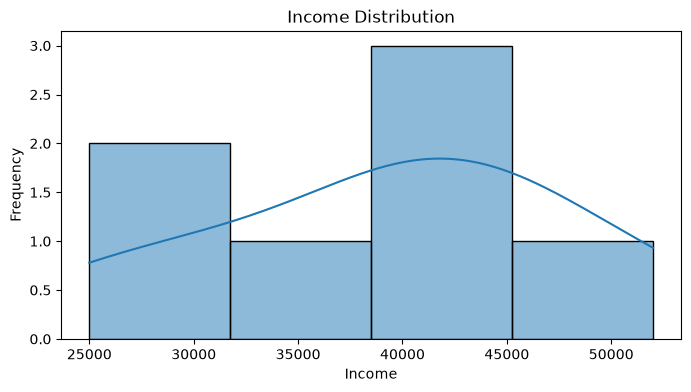

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize = (8, 4))
sns.histplot(messy_df['income'], kde = True)
plt.title("Income Distribution")
plt.xlabel("Income")
plt.ylabel("Frequency")
plt.show()

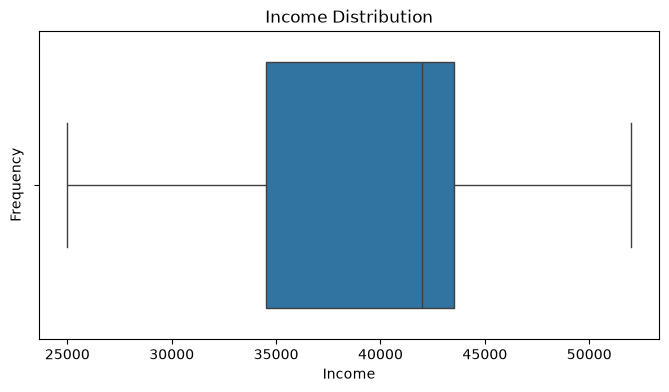

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize = (8, 4))
sns.boxplot(x = messy_df["income"])
plt.title("Income Distribution")
plt.xlabel("Income")
plt.ylabel("Frequency")
plt.show()

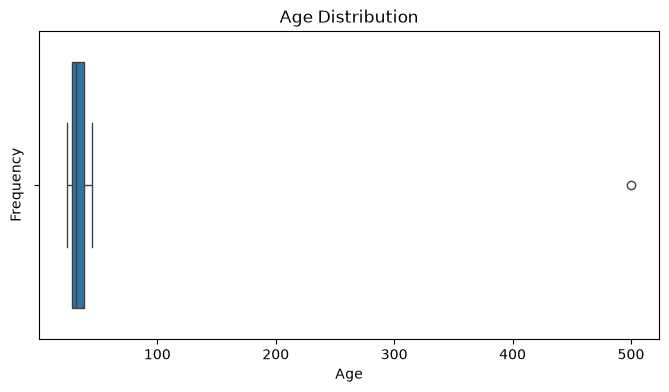

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize = (8, 4))
sns.boxplot(x = messy_df["age"])
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

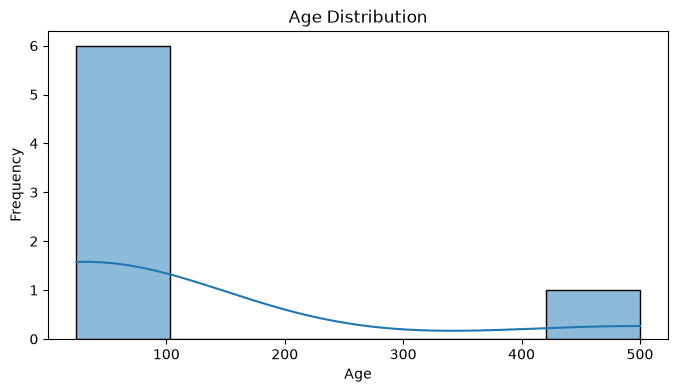

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize = (8, 4))
sns.histplot(messy_df['age'], kde = True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

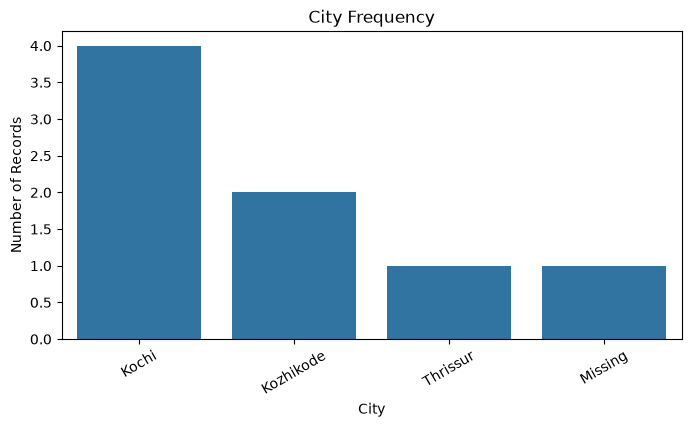

In [37]:
city_plot = messy_df["city"].fillna("Missing")
plt.figure(figsize = (8, 4))
sns.countplot(x = city_plot, order = city_plot.value_counts().index)
plt.title("City Frequency")
plt.xlabel("City")
plt.ylabel("Number of Records")
plt.xticks(rotation = 30)
plt.show()

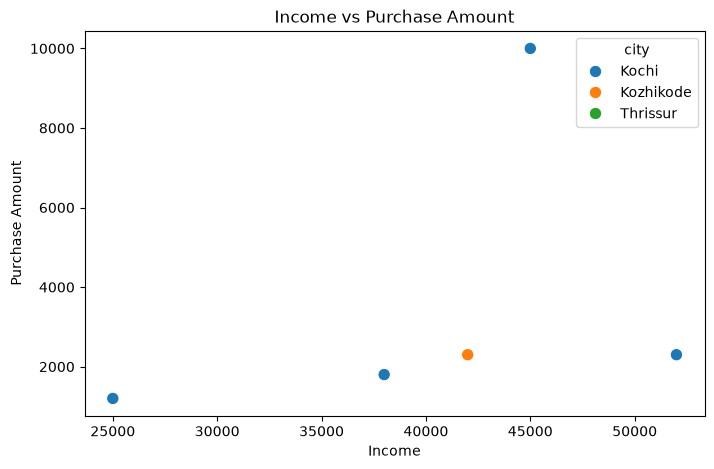

In [38]:
plt.figure(figsize = (8, 5))
sns.scatterplot(
    data = messy_df,
    x = "income",
    y = "purchase_amount",
    hue = "city",
    s= 80
)

plt.title("Income vs Purchase Amount")
plt.xlabel("Income")
plt.ylabel("Purchase Amount")
plt.show()

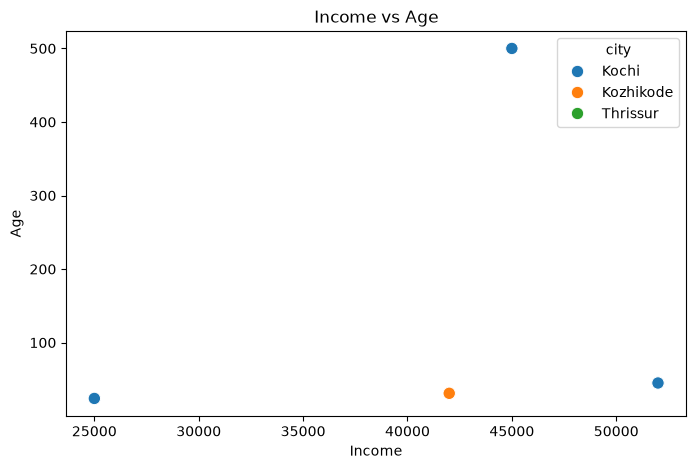

In [39]:
plt.figure(figsize = (8, 5))
sns.scatterplot(
    data = messy_df,
    x = "income",
    y = "age",
    hue = "city",
    s= 80
)

plt.title("Income vs Age")
plt.xlabel("Income")
plt.ylabel("Age")
plt.show()

In [40]:
messy_df["income"].fillna(messy_df["income"].mean())
messy_df["age"].fillna(messy_df["age"].median())
messy_df["city"].fillna(messy_df["city"].mode())

0        Kochi
1    Kozhikode
2        Kochi
3     Thrissur
4    Kozhikode
5        Kochi
6          NaN
7        Kochi
Name: city, dtype: str

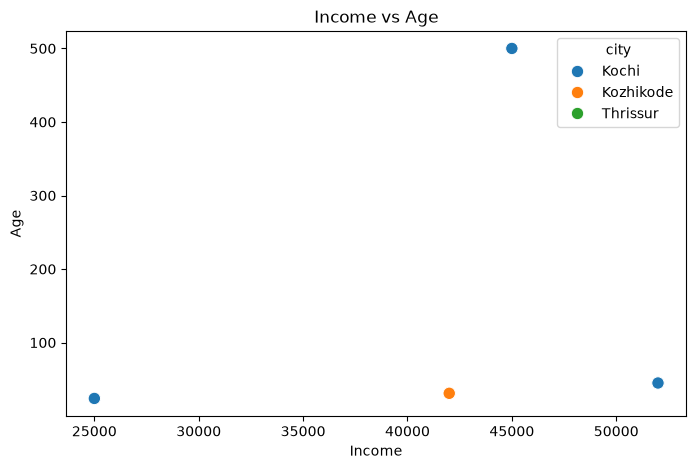

In [41]:
plt.figure(figsize = (8, 5))
sns.scatterplot(
    data = messy_df,
    x = "income",
    y = "age",
    hue = "city",
    s= 80
)

plt.title("Income vs Age")
plt.xlabel("Income")
plt.ylabel("Age")
plt.show()

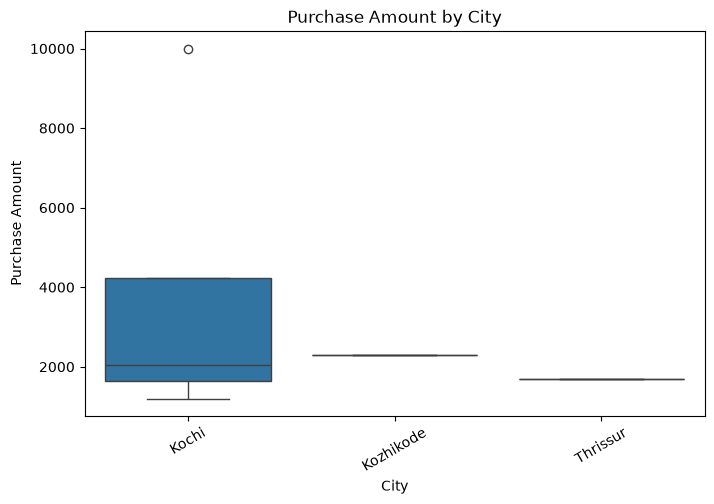

In [42]:
plt.figure(figsize = (8, 5))
sns.boxplot(
    data = messy_df,
    x = "city",
    y = "purchase_amount"
)
plt.title("Purchase Amount by City")
plt.xlabel("City")
plt.ylabel("Purchase Amount")
plt.xticks(rotation = 30)
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

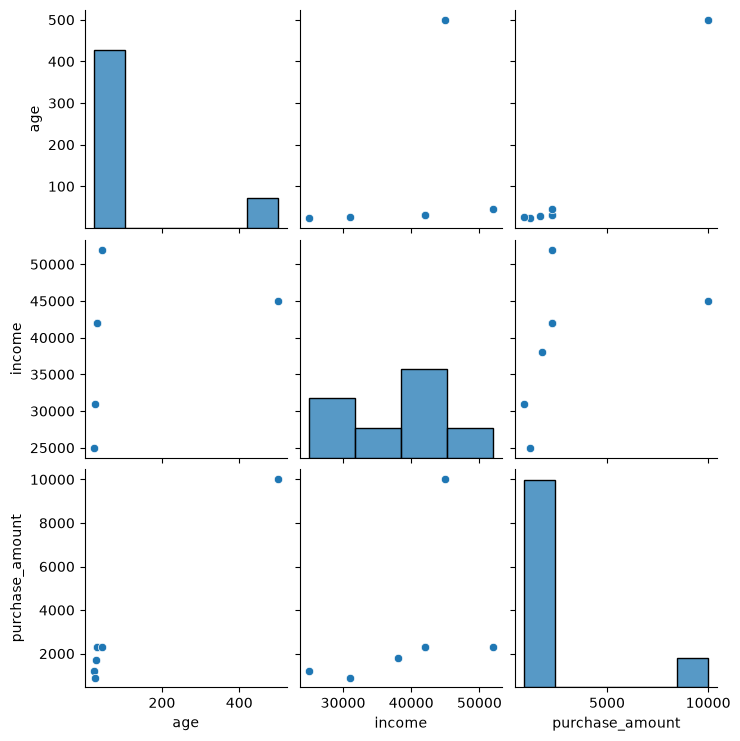

In [43]:
pairplot_df = messy_df[["age", 'income', "purchase_amount"]]
sns.pairplot(pairplot_df)
plt.show

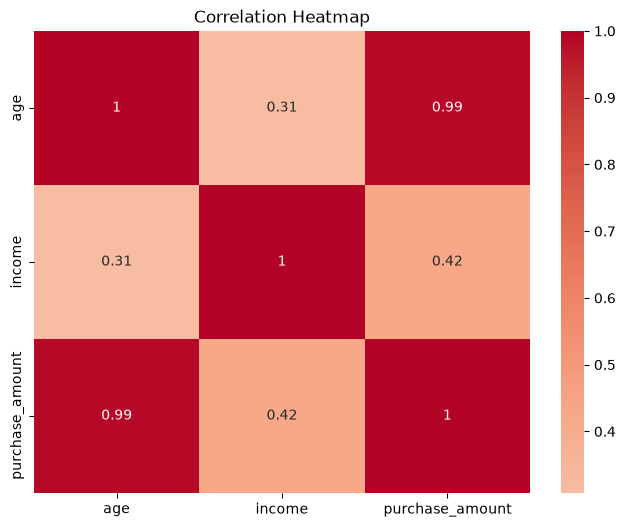

In [44]:
numeric_df = messy_df.select_dtypes(include = np.number)

plt.figure(figsize = (8, 6))
sns.heatmap(
    numeric_df.corr(numeric_only = True),
    annot = True,
    cmap = "coolwarm",
    center = 0
)
plt.title("Correlation Heatmap")
plt.show()

In [45]:
rental = pd.read_json("train.json")
display(rental)

,bathrooms,bedrooms,building_id,created,description,display_address,features,interest_level,latitude,listing_id,longitude,manager_id,photos,price,street_address
0,1.0,2,bldg_0896,2016-06-15T13:02:00,Modern 2-bedroom apartment Outdoor Space near ...,Chelsea,[Outdoor Space],medium,40.743676,6800000,-74.003101,mgr_0239,"[https://img.example.com/0_0.jpg, https://img....",3487,40 Lexington Ave
1,1.0,0,bldg_0419,2016-05-14T08:09:00,Bright Studio home Roof Deck Outdoor Space Con...,Upper West Side,"[Roof Deck, Outdoor Space, Concierge, Cats All...",low,40.787822,6800001,-73.974556,mgr_0095,"[https://img.example.com/1_0.jpg, https://img....",2843,230 5th Ave
2,1.0,1,bldg_1482,2016-06-10T09:53:00,Bright 1-bedroom unit No Fee Common Outdoor Sp...,West Village,"[No Fee, Common Outdoor Space, Pre-War, Hardwo...",high,40.735875,6800002,-74.001473,mgr_0592,"[https://img.example.com/2_0.jpg, https://img....",2653,653 Flatbush Ave
3,2.5,1,bldg_1517,2016-05-29T20:53:00,Bright 1-bedroom unit Outdoor Space Cats Allow...,Brooklyn Heights,"[Outdoor Space, Cats Allowed, Laundry in Unit,...",low,40.700124,6800003,-73.989275,mgr_0364,"[https://img.example.com/3_0.jpg, https://img....",2484,383 Broadway
4,2.5,1,bldg_0939,2016-06-27T10:53:00,Renovated 1-bedroom residence Laundry in Build...,Brooklyn Heights,"[Laundry in Building, Elevator, Common Outdoor...",medium,40.699892,6800004,-73.989818,mgr_0033,"[https://img.example.com/4_0.jpg, https://img....",2896,796 Main St
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24995,2.0,2,bldg_2336,2016-07-06T13:56:00,2-bedroom apartment Dishwasher Cats Allowed Co...,Long Island City,"[Dishwasher, Cats Allowed, Common Outdoor Spac...",low,40.739887,6824995,-73.946214,mgr_0371,"[https://img.example.com/24995_0.jpg, https://...",5588,168 Atlantic Ave
24996,1.0,0,bldg_0751,2016-04-14T19:15:00,Spacious Studio apartment Cats Allowed near tr...,Greenpoint,[Cats Allowed],low,40.729612,6824996,-73.954127,mgr_0284,"[https://img.example.com/24996_0.jpg, https://...",1800,233 Roosevelt Ave
24997,1.0,1,bldg_2179,2016-05-27T11:28:00,Sunny 1-bedroom unit Outdoor Space Pre-War wit...,SoHo,"[Outdoor Space, Pre-War]",medium,40.724646,6824997,-73.986854,mgr_0133,"[https://img.example.com/24997_0.jpg, https://...",3559,841 Flatbush Ave
24998,2.5,2,bldg_3102,2016-06-28T21:11:00,2-bedroom residence Laundry in Building Doorma...,Harlem,"[Laundry in Building, Doorman, High Speed Inte...",medium,40.811190,6824998,-73.944727,mgr_0434,"[https://img.example.com/24998_0.jpg, https://...",6837,799 Broadway


In [46]:
rental.head()

,bathrooms,bedrooms,building_id,created,description,display_address,features,interest_level,latitude,listing_id,longitude,manager_id,photos,price,street_address
0,1.0,2,bldg_0896,2016-06-15T13:02:00,Modern 2-bedroom apartment Outdoor Space near ...,Chelsea,[Outdoor Space],medium,40.743676,6800000,-74.003101,mgr_0239,"[https://img.example.com/0_0.jpg, https://img....",3487,40 Lexington Ave
1,1.0,0,bldg_0419,2016-05-14T08:09:00,Bright Studio home Roof Deck Outdoor Space Con...,Upper West Side,"[Roof Deck, Outdoor Space, Concierge, Cats All...",low,40.787822,6800001,-73.974556,mgr_0095,"[https://img.example.com/1_0.jpg, https://img....",2843,230 5th Ave
2,1.0,1,bldg_1482,2016-06-10T09:53:00,Bright 1-bedroom unit No Fee Common Outdoor Sp...,West Village,"[No Fee, Common Outdoor Space, Pre-War, Hardwo...",high,40.735875,6800002,-74.001473,mgr_0592,"[https://img.example.com/2_0.jpg, https://img....",2653,653 Flatbush Ave
3,2.5,1,bldg_1517,2016-05-29T20:53:00,Bright 1-bedroom unit Outdoor Space Cats Allow...,Brooklyn Heights,"[Outdoor Space, Cats Allowed, Laundry in Unit,...",low,40.700124,6800003,-73.989275,mgr_0364,"[https://img.example.com/3_0.jpg, https://img....",2484,383 Broadway
4,2.5,1,bldg_0939,2016-06-27T10:53:00,Renovated 1-bedroom residence Laundry in Build...,Brooklyn Heights,"[Laundry in Building, Elevator, Common Outdoor...",medium,40.699892,6800004,-73.989818,mgr_0033,"[https://img.example.com/4_0.jpg, https://img....",2896,796 Main St


In [47]:
rental.tail()

,bathrooms,bedrooms,building_id,created,description,display_address,features,interest_level,latitude,listing_id,longitude,manager_id,photos,price,street_address
24995,2.0,2,bldg_2336,2016-07-06T13:56:00,2-bedroom apartment Dishwasher Cats Allowed Co...,Long Island City,"[Dishwasher, Cats Allowed, Common Outdoor Spac...",low,40.739887,6824995,-73.946214,mgr_0371,"[https://img.example.com/24995_0.jpg, https://...",5588,168 Atlantic Ave
24996,1.0,0,bldg_0751,2016-04-14T19:15:00,Spacious Studio apartment Cats Allowed near tr...,Greenpoint,[Cats Allowed],low,40.729612,6824996,-73.954127,mgr_0284,"[https://img.example.com/24996_0.jpg, https://...",1800,233 Roosevelt Ave
24997,1.0,1,bldg_2179,2016-05-27T11:28:00,Sunny 1-bedroom unit Outdoor Space Pre-War wit...,SoHo,"[Outdoor Space, Pre-War]",medium,40.724646,6824997,-73.986854,mgr_0133,"[https://img.example.com/24997_0.jpg, https://...",3559,841 Flatbush Ave
24998,2.5,2,bldg_3102,2016-06-28T21:11:00,2-bedroom residence Laundry in Building Doorma...,Harlem,"[Laundry in Building, Doorman, High Speed Inte...",medium,40.811190,6824998,-73.944727,mgr_0434,"[https://img.example.com/24998_0.jpg, https://...",6837,799 Broadway
24999,2.0,2,bldg_3424,2016-04-05T08:54:00,Charming 2-bedroom apartment Hardwood Floors L...,Harlem,"[Hardwood Floors, Laundry in Building, Swimmin...",low,40.808701,6824999,-73.950908,mgr_0042,"[https://img.example.com/24999_0.jpg, https://...",8701,422 Lexington Ave


bathrooms : Gives the number of bathrooms in a room

bedrooms : Gives the number of bedrooms in a room

building_id : Gives the building ID

created : Date of room creation

description : a simple description of the room layout

display_address : Address of the building in the site

features : Important appliances and objects in the room

interest_level : Rate of interest

latitude : Vertical Coords

listing_id : Room listing ID

longitude : Horizontal Coords

manager_id : Manager ID

photos: images of the room

price: Room price

street_address : physical Location of room



In [48]:
rental.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   bathrooms        25000 non-null  float64
 1   bedrooms         25000 non-null  int64  
 2   building_id      25000 non-null  str    
 3   created          25000 non-null  str    
 4   description      25000 non-null  str    
 5   display_address  25000 non-null  str    
 6   features         25000 non-null  object 
 7   interest_level   25000 non-null  str    
 8   latitude         25000 non-null  float64
 9   listing_id       25000 non-null  int64  
 10  longitude        25000 non-null  float64
 11  manager_id       25000 non-null  str    
 12  photos           25000 non-null  object 
 13  price            25000 non-null  int64  
 14  street_address   25000 non-null  str    
dtypes: float64(3), int64(3), object(2), str(7)
memory usage: 2.9+ MB


In [49]:
rental.describe()

,bathrooms,bedrooms,latitude,listing_id,longitude,price
count,25000.00000,25000.000000,25000.000000,2.500000e+04,25000.000000,25000.000000
mean,1.60728,1.185760,40.736858,6.812500e+06,-73.971151,3974.746200
std,0.68493,1.056947,0.035651,7.217023e+03,0.027599,1741.916393
min,1.00000,0.000000,40.658720,6.800000e+06,-74.020673,1300.000000
25%,1.00000,0.000000,40.712646,6.806250e+06,-73.995791,2701.000000
50%,1.50000,1.000000,40.733418,6.812500e+06,-73.977007,3640.000000
75%,2.00000,2.000000,40.759844,6.818749e+06,-73.951322,4866.000000
max,3.00000,4.000000,40.822954,6.824999e+06,-73.903218,18000.000000


In [50]:
rental.shape

(25000, 15)

In [51]:
rental.dtypes

bathrooms          float64
bedrooms             int64
building_id            str
created                str
description            str
display_address        str
features            object
interest_level         str
latitude           float64
listing_id           int64
longitude          float64
manager_id             str
photos              object
price                int64
street_address         str
dtype: object

In [52]:
rental['bedrooms'].describe()


count    25000.000000
mean         1.185760
std          1.056947
min          0.000000
25%          0.000000
50%          1.000000
75%          2.000000
max          4.000000
Name: bedrooms, dtype: float64

In [53]:
rental['bedrooms'].info()

<class 'pandas.Series'>
RangeIndex: 25000 entries, 0 to 24999
Series name: bedrooms
Non-Null Count  Dtype
--------------  -----
25000 non-null  int64
dtypes: int64(1)
memory usage: 195.4 KB


In [54]:
rental['bedrooms'].head()

0    2
1    0
2    1
3    1
4    1
Name: bedrooms, dtype: int64

In [55]:
def safe_list_length(value) :
  if isinstance(value , (list, tuple)):
    return len(value)
    return 0

rental["feature_count"] = rental["features"].apply(safe_list_length)
rental["photo_count"] = rental["photos"].apply(safe_list_length)

rental["created"] = pd.to_datetime(rental["created"], errors = "coerce")
rental["listing_hour"] = rental["created"].dt.hour
rental["listing_dayofweek"] = rental["created"].dt.dayofweek

display(
    rental[
        ["bedrooms", "bathrooms", "price",
         "feature_count", "photo_count",
         "listing_hour", "listing_dayofweek",
         "interest_level" ]
        ].head()
)


,bedrooms,bathrooms,price,feature_count,photo_count,listing_hour,listing_dayofweek,interest_level
0,2,1.0,3487,1,3,13,2,medium
1,0,1.0,2843,4,4,8,5,low
2,1,1.0,2653,5,4,9,4,high
3,1,2.5,2484,4,5,20,6,low
4,1,2.5,2896,5,4,10,0,medium


In [56]:
rental.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   bathrooms          25000 non-null  float64       
 1   bedrooms           25000 non-null  int64         
 2   building_id        25000 non-null  str           
 3   created            25000 non-null  datetime64[us]
 4   description        25000 non-null  str           
 5   display_address    25000 non-null  str           
 6   features           25000 non-null  object        
 7   interest_level     25000 non-null  str           
 8   latitude           25000 non-null  float64       
 9   listing_id         25000 non-null  int64         
 10  longitude          25000 non-null  float64       
 11  manager_id         25000 non-null  str           
 12  photos             25000 non-null  object        
 13  price              25000 non-null  int64         
 14  street_address   

In [57]:
rental.describe()

,bathrooms,bedrooms,created,latitude,listing_id,longitude,price,feature_count,photo_count,listing_hour,listing_dayofweek
count,25000.00000,25000.000000,25000,25000.000000,2.500000e+04,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000
mean,1.60728,1.185760,2016-05-31 12:37:12.290400,40.736858,6.812500e+06,-73.971151,3974.746200,4.019680,4.983480,11.565600,3.019040
min,1.00000,0.000000,2016-04-01 00:00:00,40.658720,6.800000e+06,-74.020673,1300.000000,0.000000,0.000000,0.000000,0.000000
25%,1.00000,0.000000,2016-05-01 01:17:15,40.712646,6.806250e+06,-73.995791,2701.000000,3.000000,3.000000,6.000000,1.000000
50%,1.50000,1.000000,2016-05-31 14:25:00,40.733418,6.812500e+06,-73.977007,3640.000000,4.000000,5.000000,12.000000,3.000000
75%,2.00000,2.000000,2016-07-01 02:50:30,40.759844,6.818749e+06,-73.951322,4866.000000,5.000000,6.000000,18.000000,5.000000
max,3.00000,4.000000,2016-07-30 23:45:00,40.822954,6.824999e+06,-73.903218,18000.000000,12.000000,16.000000,23.000000,6.000000
std,0.68493,1.056947,NaN,0.035651,7.217023e+03,0.027599,1741.916393,2.011332,2.232534,6.939979,1.989783


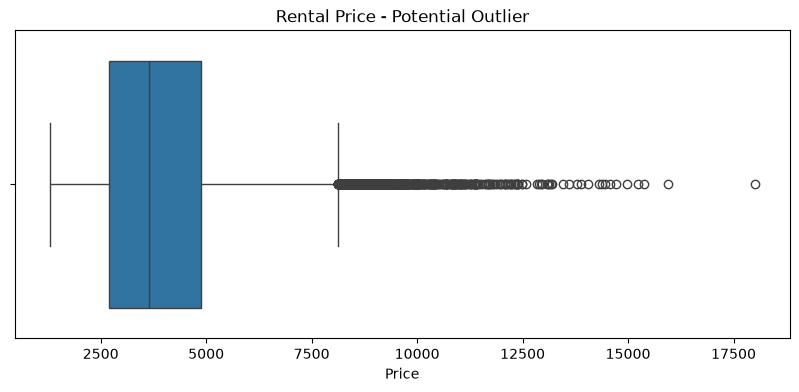

Price quantities: 


,price
0.00,1300.00
0.25,2701.00
0.50,3640.00
0.75,4866.00
0.90,6270.10
0.99,9504.23
1.00,18000.00


In [58]:
plt.figure(figsize = (10, 4))
sns.boxplot(x = rental["price"])
plt.title("Rental Price - Potential Outlier")
plt.xlabel("Price")
plt.show()

print("Price quantities: ")
display(rental["price"].quantile([0, 0.25, 0.5, 0.75, 0.9, 0.99, 1]).to_frame("price"))

Potential Outliers have been observed on the right side. Hence, the data must be right skewed

,count
interest_level,
low,13757
medium,8480
high,2763


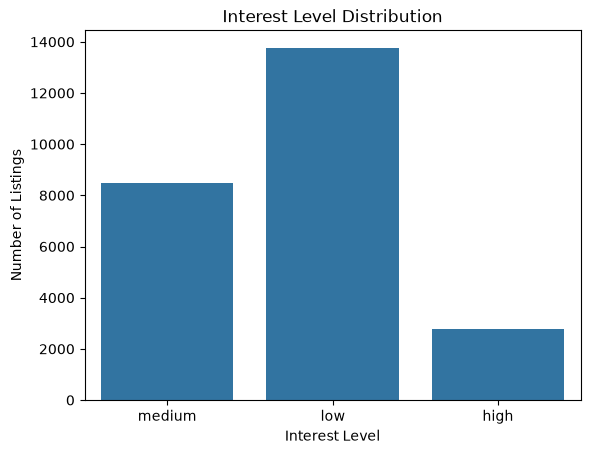

In [59]:
target_counts = rental["interest_level"].value_counts()

display(target_counts.to_frame("count"))

sns.countplot(
    data = rental,
    x = "interest_level"
)

plt.title("Interest Level Distribution")
plt.xlabel("Interest Level")
plt.ylabel("Number of Listings")
plt.show()

Target distribution via Count Plot

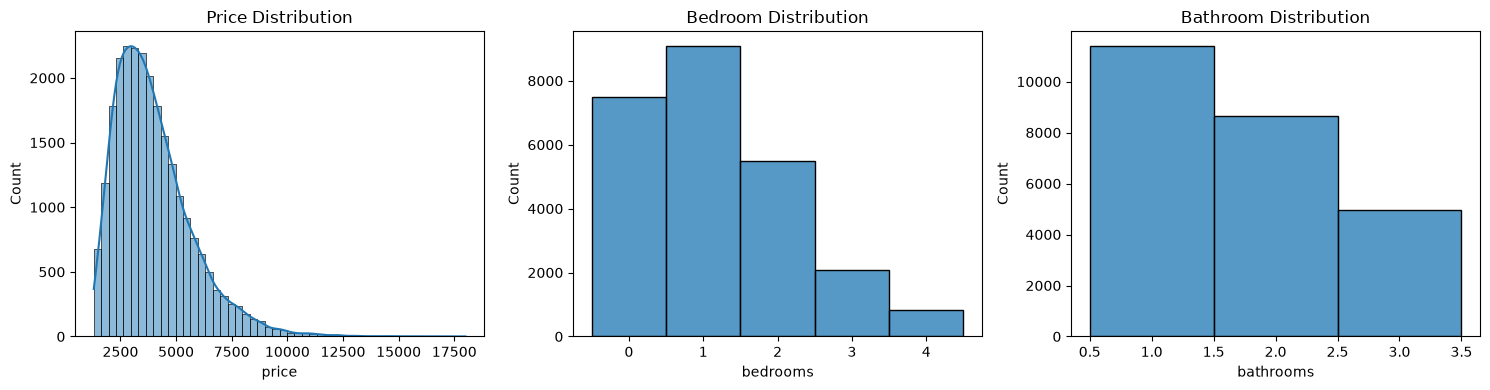

In [60]:
fig, axes = plt.subplots(1, 3, figsize = (15, 4))

sns.histplot(
    rental["price"],
    bins = 50,
    kde = True,
    ax = axes[0]
)
axes[0].set_title("Price Distribution")

sns.histplot(
    rental['bedrooms'],
    discrete = True,
    ax = axes[1]
)
axes[1].set_title("Bedroom Distribution")

sns.histplot(
    rental['bathrooms'],
    discrete = True,
    ax = axes[2]
)
axes[2].set_title("Bathroom Distribution")

plt.tight_layout()
plt.show()


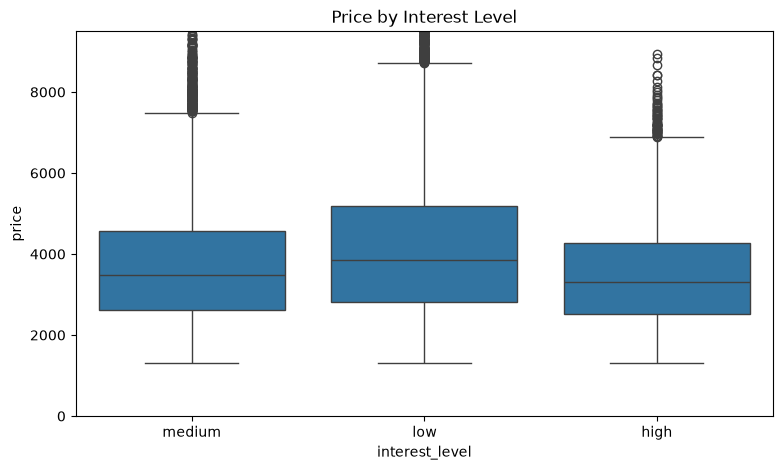

In [61]:
plt.figure(figsize = (9, 5))

sns.boxplot(
    data = rental,
    x = "interest_level",
    y = "price"
)

# Hide the most extreme 1% so the central pattern isv isible
plt.ylim(0, rental["price"].quantile(0.99))
plt.title("Price by Interest Level")
plt.show()

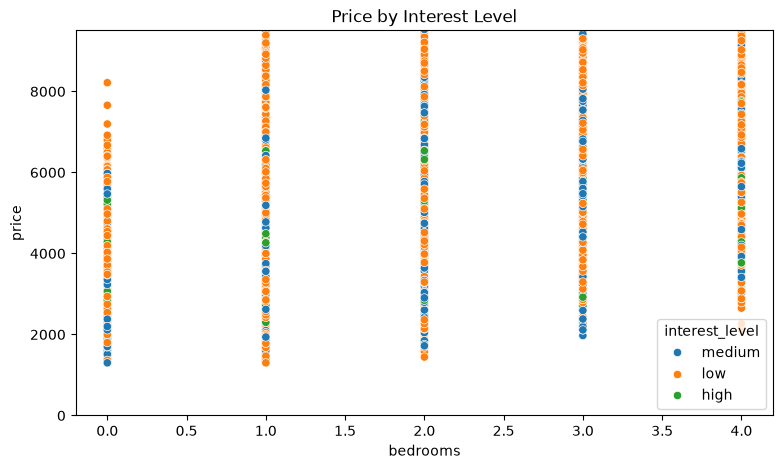

In [62]:
plt.figure(figsize = (9, 5))

sns.scatterplot(
    data = rental,
    x = "bedrooms",
    y = "price",
    hue = "interest_level"
)

# Hide the most extreme 1% so the central pattern i svisible
plt.ylim(0, rental["price"].quantile(0.99))
plt.title("Price by Interest Level")
plt.show()

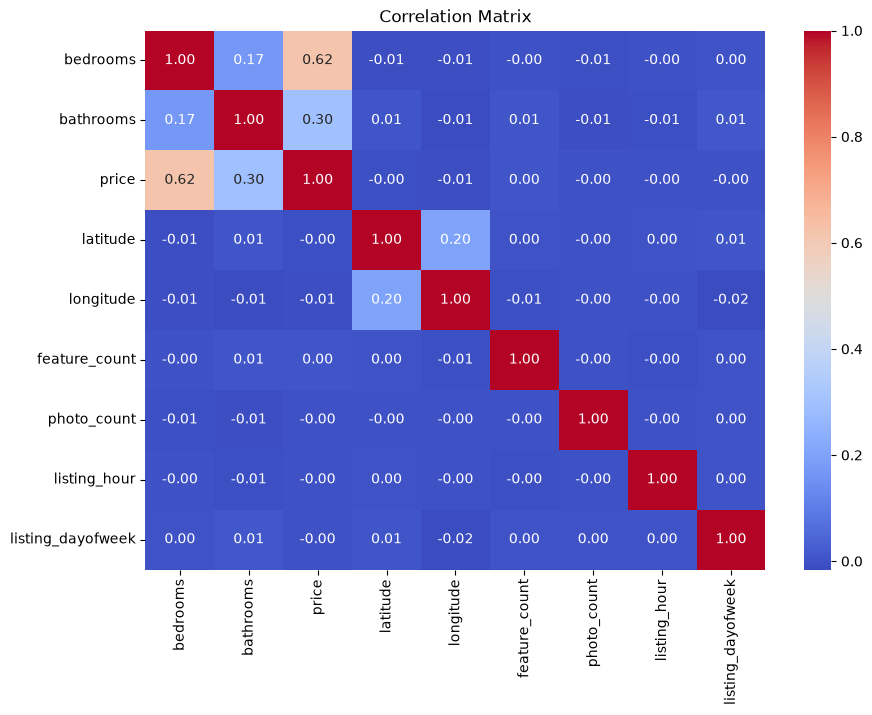

In [63]:
numeric_columns = [
    "bedrooms", "bathrooms", "price",
    "latitude", "longitude",
    "feature_count", "photo_count",
    "listing_hour", "listing_dayofweek"
]

plt.figure(figsize = (10, 7))
sns.heatmap(
    rental[numeric_columns].corr(),
    annot = True,
    cmap = "coolwarm",
    fmt = ".2f"
)

plt.title("Correlation Matrix")
plt.show()

In [64]:
basic_features = [
    "bedrooms", "bathrooms", "price",
    "latitude", "longitude",
    "feature_count", "photo_count",
    "listing_hour", "listing_dayofweek"
]

X_basic = rental[basic_features]
y = rental["interest_level"].copy()

print("X: ", X_basic.shape)
print("Y: ", y.shape)


X:  (25000, 9)
Y:  (25000,)


In [65]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_basic,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

print(" Training: ", X_train.shape)
print("Testing: ", X_test.shape)

 Training:  (20000, 9)
Testing:  (5000, 9)


In [66]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_preprocessor = Pipeline(steps = [
    ("imputer", SimpleImputer(strategy = "median")),
    ("scaler", StandardScaler())
])

print("Numerical processing pipeline created.")

Numerical processing pipeline created.


In [67]:
from sklearn.linear_model import LogisticRegression

logistic_basic = Pipeline([  # Create logistic regression pipeline
    ("preprocessing", numeric_preprocessor),
    ("model", LogisticRegression(max_iter = 1000))
])

logistic_basic.fit(X_train, y_train) # Learn the parameters from data

basic_pred = logistic_basic.predict(X_test) # Predict the result from training data

print("Baseline Logistic Regression trained")

Baseline Logistic Regression trained


Accuracy:  0.573
Macro F1 Score:  0.366

Classification Report: 

              precision    recall  f1-score   support

        high       0.28      0.01      0.03       553
         low       0.62      0.85      0.72      2751
      medium       0.43      0.30      0.35      1696

    accuracy                           0.57      5000
   macro avg       0.44      0.39      0.37      5000
weighted avg       0.52      0.57      0.52      5000



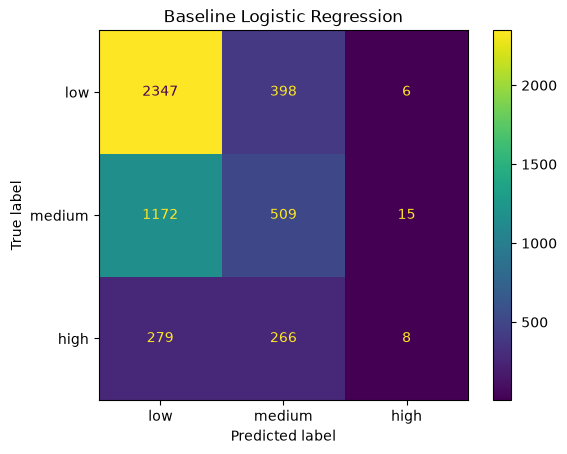

In [68]:
from sklearn.metrics import(
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

print("Accuracy: ", round(accuracy_score(y_test, basic_pred), 3))
print("Macro F1 Score: ", round(f1_score(y_test, basic_pred, average = "macro"), 3))

print("\nClassification Report: \n")
print(classification_report(y_test, basic_pred, zero_division = 0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    basic_pred,
    labels = ["low", "medium", "high"],
    display_labels = ["low", "medium", "high"]
)

plt.title("Baseline Logistic Regression")
plt.show()



In [69]:
from sklearn.feature_extraction.text import TfidfVectorizer

tf_idf_demo = TfidfVectorizer(
    stop_words = "english",
    max_features = 20
)

# Fill missing descriptions only for this demonstration
text_demo = rental["description"].fillna("").astype(str)

tf_idf_matrix_demo = tf_idf_demo.fit_transform(text_demo)

print("TF-IDF Matrix shape: ", tf_idf_matrix_demo.shape)
print("Example vocabulary: ")
print(tf_idf_demo.get_feature_names_out()[ : 20])




TF-IDF Matrix shape:  (25000, 20)
Example vocabulary: 
['allowed' 'apartment' 'bedroom' 'convenient' 'great' 'home' 'laundry'
 'light' 'natural' 'near' 'neighborhood' 'outdoor' 'parks' 'residence'
 'restaurants' 'shops' 'space' 'studio' 'transit' 'unit']


In [70]:
# Create seperate feature groups
numeric_features = basic_features
text_features = "description"

text_preprocessor = TfidfVectorizer(
    stop_words = "english",
    max_features = 1000,
    ngram_range = (1, 2)
)

from sklearn.compose import ColumnTransformer

combined_preprocessor = ColumnTransformer(
    transformers = [
    ("numeric", numeric_preprocessor, numeric_features),
    ("text", text_preprocessor, text_features)
    ],
    remainder = "drop"
)

print("Combined numerical + TF-IDF preprocessor created.")


Combined numerical + TF-IDF preprocessor created.


In [71]:
# Build X using the original columns required by the combined preprocessor
X_combined = rental[numeric_features + [text_features]].copy()

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_combined,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

logistic_tf_idf = Pipeline([
    ("preprocessing", combined_preprocessor),
    ("model", LogisticRegression(
        max_iter = 1000,
        C = 1.0
    ))
])

logistic_tf_idf.fit(X_train_c, y_train_c)

tf_idf_pred = logistic_tf_idf.predict(X_test_c)

print("TF-IDF + Logistic Regression trained")
print("Accuracy: ", round(accuracy_score(y_test_c, tf_idf_pred), 3))
print("Macro F1 Score: ", round(f1_score(y_test_c, tf_idf_pred, average = "macro"), 3))

print("\nClassification Report: \n")
print(classification_report(y_test, tf_idf_pred, zero_division = 0))


TF-IDF + Logistic Regression trained
Accuracy:  0.583
Macro F1 Score:  0.4

Classification Report: 

              precision    recall  f1-score   support

        high       0.31      0.05      0.08       553
         low       0.64      0.83      0.72      2751
      medium       0.45      0.35      0.40      1696

    accuracy                           0.58      5000
   macro avg       0.47      0.41      0.40      5000
weighted avg       0.54      0.58      0.54      5000



In [72]:
regression_model_comparison = pd.DataFrame({
    "Model" : [
        "Baseline Logistic Regression",
        "TF-IDF + Logistic Regression"
    ],
    "Accuracy" : [
        accuracy_score(y_test, basic_pred),
        accuracy_score(y_test_c, tf_idf_pred)
    ],
    "Macro F1 Score" : [
        f1_score(y_test, basic_pred, average = "macro"),
        f1_score(y_test_c, tf_idf_pred, average = "macro")
    ]
})

display(regression_model_comparison.sort_values(by = "Macro F1 Score", ascending = False))

,Model,Accuracy,Macro F1 Score
1,TF-IDF + Logistic Regression,0.5832,0.399646
0,Baseline Logistic Regression,0.5728,0.366357


In [73]:
from sklearn.ensemble import RandomForestClassifier

random_forest_basic = Pipeline([
    ("preprocessing", numeric_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators = 150,
        random_state = 42,
        n_jobs = -1
    ))
])

random_forest_basic.fit(X_train, y_train)
rf_basic_pred = random_forest_basic.predict(X_test)

print("Baseline Random Forest")
print("Accuracy: ", round(accuracy_score(y_test, rf_basic_pred), 3))
print("Macro F1 Score: ", round(f1_score(y_test, rf_basic_pred, average = "macro"), 3))

Baseline Random Forest
Accuracy:  0.579
Macro F1 Score:  0.42


In [74]:
from sklearn.ensemble import RandomForestClassifier

random_forest_combined = Pipeline([
    ("preprocessing", combined_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators = 150,
        random_state = 42,
        n_jobs = -1
    ))
])

random_forest_combined.fit(X_train_c, y_train_c)
rf_combined_pred = random_forest_combined.predict(X_test_c)

print("Combined Random Forest")
print("Accuracy: ", round(accuracy_score(y_test_c, rf_combined_pred), 3))
print("Macro F1 Score: ", round(f1_score(y_test_c, rf_combined_pred, average = "macro"), 3))

Combined Random Forest
Accuracy:  0.587
Macro F1 Score:  0.386


In [75]:
rf_model_comparison = pd.DataFrame({
    "Model" : [
        "Baseline Random Forest",
        "Combined Random Forest"
    ],
    "Accuracy" : [
        accuracy_score(y_test, rf_basic_pred),
        accuracy_score(y_test_c, rf_combined_pred)
    ],
    "Macro F1 Score" : [
        f1_score(y_test, rf_basic_pred, average = "macro"),
        f1_score(y_test_c, rf_combined_pred, average = "macro")
    ]
})

display(rf_model_comparison.sort_values(by = "Macro F1 Score", ascending = False))

,Model,Accuracy,Macro F1 Score
0,Baseline Random Forest,0.579,0.420413
1,Combined Random Forest,0.587,0.385970


In [76]:
combined_model_comparison = (
    pd.concat([
        regression_model_comparison,
        rf_model_comparison
    ])
    .sort_values(by="Macro F1 Score", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

display(combined_model_comparison)

,Model,Accuracy,Macro F1 Score
0,Baseline Random Forest,0.5790,0.4204
1,TF-IDF + Logistic Regression,0.5832,0.3996
2,Combined Random Forest,0.5870,0.3860
3,Baseline Logistic Regression,0.5728,0.3664


# **Lines 64 to 76 is test code for concepts studied in 7/10/26. The lines after this text will be based on the concepts studied in 8/10/26**

In [77]:
def safe_list_length(value):
    if isinstance(value, list):
        return len(value)
    return 0

def features_to_text(value):
    if isinstance(value, list):
        return " ".join(str(item) for item in value)
    return ""

rental["feature_count"] = rental["features"].apply(safe_list_length)
rental["photo_count"] = rental["photos"].apply(safe_list_length)

# Original features list -> Clean text
basic_features = [
    "bedrooms", "bathrooms", "price",
    "latitude", "longitude",
    "feature_count", "photo_count",
    "listing_hour", "listing_dayofweek"
]

rental["features_text"] = rental["features"].apply(features_to_text)

display(
    rental[
        ["features", "features_text", "feature_count",
        "photos", "photo_count"]
    ].head()
)

,features,features_text,feature_count,photos,photo_count
0,[Outdoor Space],Outdoor Space,1,"[https://img.example.com/0_0.jpg, https://img....",3
1,"[Roof Deck, Outdoor Space, Concierge, Cats All...",Roof Deck Outdoor Space Concierge Cats Allowed,4,"[https://img.example.com/1_0.jpg, https://img....",4
2,"[No Fee, Common Outdoor Space, Pre-War, Hardwo...",No Fee Common Outdoor Space Pre-War Hardwood F...,5,"[https://img.example.com/2_0.jpg, https://img....",4
3,"[Outdoor Space, Cats Allowed, Laundry in Unit,...",Outdoor Space Cats Allowed Laundry in Unit Roo...,4,"[https://img.example.com/3_0.jpg, https://img....",5
4,"[Laundry in Building, Elevator, Common Outdoor...",Laundry in Building Elevator Common Outdoor Sp...,5,"[https://img.example.com/4_0.jpg, https://img....",4


In [78]:
from sklearn.model_selection import train_test_split

X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_basic,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

print(" Training: ", X_train.shape)
print("Testing: ", X_test.shape)

 Training:  (20000, 9)
Testing:  (5000, 9)


In [79]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

new_numeric_preprocessor = Pipeline(steps = [
    ("imputer", SimpleImputer(strategy = "median")),
    ("scaler", StandardScaler())
])

print("Numerical processing pipeline created.")

Numerical processing pipeline created.


In [80]:
from sklearn.linear_model import LogisticRegression

logistic_basic_new = Pipeline([  # Create logistic regression pipeline
    ("preprocessing", new_numeric_preprocessor),
    ("model", LogisticRegression(max_iter = 1000))
])

logistic_basic_new.fit(X_train_new, y_train_new) # Learn the parameters from data

basic_pred_new = logistic_basic.predict(X_test_new) # Predict the result from training data

print("Baseline Logistic Regression trained")

Baseline Logistic Regression trained


In [81]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF 
tf_idf_demo = TfidfVectorizer(
    stop_words = "english",
    max_features = 20
)

tf_idf = TfidfVectorizer(
    stop_words = "english",
    max_features = 20
)

# Fill missing descriptions only for this demonstration
text_demo = rental["description"].fillna("").astype(str)

# Add features_text variable
features_to_text = rental["features_text"].fillna("").astype(str)

# Add & Apply demo matrix parameters
tf_idf_matrix_demo = tf_idf_demo.fit_transform(text_demo)

# Add & Apply features_text paramaters
tf_idf_features_to_text = tf_idf.fit_transform(features_to_text)

print("TF-IDF Matrix shape: ", tf_idf_matrix_demo.shape)
print("Example vocabulary: ")
print(tf_idf_demo.get_feature_names_out()[ : 20])

print("\nTF-IDF Features to Text shape: ", tf_idf_features_to_text.shape)
print("Example vocabulary: ")
print(tf_idf.get_feature_names_out()[ : 20])

TF-IDF Matrix shape:  (25000, 20)
Example vocabulary: 
['allowed' 'apartment' 'bedroom' 'convenient' 'great' 'home' 'laundry'
 'light' 'natural' 'near' 'neighborhood' 'outdoor' 'parks' 'residence'
 'restaurants' 'shops' 'space' 'studio' 'transit' 'unit']

TF-IDF Features to Text shape:  (25000, 20)
Example vocabulary: 
['allowed' 'cats' 'center' 'concierge' 'dishwasher' 'dogs' 'doorman'
 'elevator' 'fee' 'floors' 'hardwood' 'high' 'internet' 'laundry'
 'outdoor' 'pool' 'space' 'speed' 'swimming' 'unit']


In [82]:
# Create seperate feature groups
new_numeric_features = basic_features
text_features = "description"
new_text_features = "features_text"

text_preprocessor = TfidfVectorizer(
    stop_words = "english",
    max_features = 1000,
    ngram_range = (1, 2)
)

new_text_preprocessor = TfidfVectorizer(
    stop_words = "english",
    max_features = 1000,
    ngram_range = (1, 2)
)

from sklearn.compose import ColumnTransformer

new_combined_preprocessor = ColumnTransformer(
    transformers = [
    ("numeric", new_numeric_preprocessor, new_numeric_features),
    ("text", text_preprocessor, text_features),
    ("features text", new_text_preprocessor, new_text_features)
    ],
    remainder = "drop"
)

print("Combined numerical + TF-IDF preprocessor created.")

Combined numerical + TF-IDF preprocessor created.


In [83]:
# Build X using the original columns required by the combined preprocessor
X_combined_new = rental[new_numeric_features + [text_features] + [new_text_features]].copy()

X_train_c_new, X_test_c_new, y_train_c_new, y_test_c_new = train_test_split(
    X_combined_new,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

logistic_tf_idf = Pipeline([
    ("preprocessing", new_combined_preprocessor),
    ("model", LogisticRegression(
        max_iter = 1000,
        C = 1.0
    ))
])

logistic_tf_idf.fit(X_train_c_new, y_train_c_new)

tf_idf_pred_new = logistic_tf_idf.predict(X_test_c_new)

print("TF-IDF + Logistic Regression trained")
print("Accuracy: ", round(accuracy_score(y_test_c_new, tf_idf_pred_new), 3))
print("Macro F1 Score: ", round(f1_score(y_test_c_new, tf_idf_pred_new, average = "macro"), 3))

print("\nClassification Report: \n")
print(classification_report(y_test_new, tf_idf_pred_new, zero_division = 0))


TF-IDF + Logistic Regression trained
Accuracy:  0.587
Macro F1 Score:  0.423

Classification Report: 

              precision    recall  f1-score   support

        high       0.36      0.08      0.14       553
         low       0.65      0.82      0.72      2751
      medium       0.46      0.37      0.41      1696

    accuracy                           0.59      5000
   macro avg       0.49      0.42      0.42      5000
weighted avg       0.55      0.59      0.55      5000



In [84]:
new_regression_model_comparison = pd.DataFrame({
    "Model" : [
        "Baseline Logistic Regression",
        "TF-IDF + Logistic Regression"
    ],
    "Accuracy" : [
        accuracy_score(y_test_new, basic_pred_new),
        accuracy_score(y_test_c_new, tf_idf_pred_new)
    ],
    "Macro F1 Score" : [
        f1_score(y_test_new, basic_pred_new, average = "macro"),
        f1_score(y_test_c_new, tf_idf_pred_new, average = "macro")
    ]
})

display(new_regression_model_comparison.sort_values(by = "Macro F1 Score", ascending = False))

,Model,Accuracy,Macro F1 Score
1,TF-IDF + Logistic Regression,0.5870,0.422608
0,Baseline Logistic Regression,0.5728,0.366357


In [85]:
from sklearn.ensemble import RandomForestClassifier

new_random_forest_basic = Pipeline([
    ("preprocessing", new_numeric_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators = 150,
        random_state = 42,
        n_jobs = -1
    ))
])

new_random_forest_basic.fit(X_train_new, y_train_new)
rf_basic_pred_new = new_random_forest_basic.predict(X_test_new)

print("Baseline Random Forest")
print("Accuracy: ", round(accuracy_score(y_test_new, rf_basic_pred_new), 3))
print("Macro F1 Score: ", round(f1_score(y_test_new, rf_basic_pred_new, average = "macro"), 3))

Baseline Random Forest
Accuracy:  0.579
Macro F1 Score:  0.42


In [86]:
from sklearn.ensemble import RandomForestClassifier

new_random_forest_combined = Pipeline([
    ("preprocessing", new_combined_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators = 150,
        random_state = 42,
        n_jobs = -1
    ))
])

new_random_forest_combined.fit(X_train_c_new, y_train_c_new)
new_rf_combined_pred = new_random_forest_combined.predict(X_test_c_new)

print("Combined Random Forest")
print("Accuracy: ", round(accuracy_score(y_test_c_new, new_rf_combined_pred), 3))
print("Macro F1 Score: ", round(f1_score(y_test_c_new, new_rf_combined_pred, average = "macro"), 3))

Combined Random Forest
Accuracy:  0.59
Macro F1 Score:  0.399


In [87]:
new_rf_model_comparison = pd.DataFrame({
    "Model" : [
        "Baseline Random Forest",
        "Combined Random Forest"
    ],
    "Accuracy" : [
        accuracy_score(y_test_new, rf_basic_pred_new),
        accuracy_score(y_test_c_new, new_rf_combined_pred)
    ],
    "Macro F1 Score" : [
        f1_score(y_test_new, rf_basic_pred_new, average = "macro"),
        f1_score(y_test_c_new, new_rf_combined_pred, average = "macro")
    ]
})

display(new_rf_model_comparison.sort_values(by = "Macro F1 Score", ascending = False))

,Model,Accuracy,Macro F1 Score
0,Baseline Random Forest,0.5790,0.420413
1,Combined Random Forest,0.5904,0.399205


In [88]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy = "most_frequent")

dummy.fit(X_train_c_new, y_train_c_new)

dummy_pred = dummy.predict(X_test_c_new)

print(
    "Majority Baseline Accuracy: ",
    round(accuracy_score(y_test_c_new, dummy_pred), 4)
)

print(
    "Majority Baseline Macro F1: ",
    round(f1_score(
        y_test_c_new,
        dummy_pred,
        average = "macro"
    ), 4)
)

Majority Baseline Accuracy:  0.5502
Majority Baseline Macro F1:  0.2366


In [89]:
balanced_logistic = Pipeline([
    ("preprocessor", new_combined_preprocessor),
    ("classifier", LogisticRegression(
        C = 1.0,
        class_weight = "balanced",
        max_iter = 1000
    ))
])

balanced_logistic.fit(X_train_c_new, y_train_c_new)

balanced_pred = balanced_logistic.predict(X_test_c_new)

print(
    "Balanced Accuracy: ",
    round(accuracy_score(y_test_c_new, balanced_pred), 4)
)

print(
    "Balanced Macro F1: ",
    round(f1_score(
        y_test_c_new,
        balanced_pred,
        average = "macro"
    ), 4)
)

print("\n")

print(classification_report(
    y_test_c_new,
    balanced_pred
))

Balanced Accuracy:  0.501
Balanced Macro F1:  0.4418


              precision    recall  f1-score   support

        high       0.23      0.55      0.32       553
         low       0.70      0.61      0.65      2751
      medium       0.41      0.31      0.35      1696

    accuracy                           0.50      5000
   macro avg       0.45      0.49      0.44      5000
weighted avg       0.55      0.50      0.51      5000



In [90]:
from sklearn.model_selection import cross_val_score
cv_scores = cross_val_score(
    balanced_logistic,
    X_train_c_new,
    y_train_c_new,
    cv = 5,
    scoring = "f1_macro",
    n_jobs = -1
)

print("Fold Macro F1 scores: ")
print(cv_scores)

print("\nMean: ",
     round(cv_scores.mean(), 4))

print("Standard Deviation: ", 
     round(cv_scores.std(), 4))

Fold Macro F1 scores: 
[0.42639807 0.43060323 0.425599   0.43399006 0.44078654]

Mean:  0.4315
Standard Deviation:  0.0056


In [91]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

full_pipeline = Pipeline(steps=[
    ("preprocessing", new_combined_preprocessor),
    ("classifier", LogisticRegression(random_state=42))
])

parameter_grid = {
    "classifier__C" : [
        0.01,
        0.1,
        1,
        10,
        100
    ],
    "classifier__class_weight" : [
        None,
        "balanced"
    ]
}

grid_search = GridSearchCV(
    estimator = full_pipeline,
    param_grid = parameter_grid,
    cv = 5,
    scoring = "f1_macro",
    n_jobs = -1,
    verbose = 1
)

grid_search.fit(X_train_c_new, y_train_c_new)

print("Best parameters: ")
print(grid_search.best_params_)

print(
    "\nBest CV Macro F1 :",
    round(grid_search.best_score_, 4)
)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters: 
{'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}

Best CV Macro F1 : 0.4387


In [92]:
grid_pred = grid_search.best_estimator_.predict(X_test_c_new)

grid_accuracy = accuracy_score(
    y_test_c_new,
    grid_pred
)

grid_macro_f1 = f1_score(
    y_test_c_new,
    grid_pred,
    average = "macro"
)

print(
    "GridSearch Test Accuracy:",
    round(grid_accuracy, 4)
)

print(
    "GridSearch Test Macro F1:",
    round(grid_macro_f1, 4)
)

print("\nClassification Report:")
print(classification_report(
        y_test_c_new,
        grid_pred
))

GridSearch Test Accuracy: 0.5046
GridSearch Test Macro F1: 0.443

Classification Report:
              precision    recall  f1-score   support

        high       0.23      0.59      0.33       553
         low       0.71      0.63      0.67      2751
      medium       0.41      0.28      0.33      1696

    accuracy                           0.50      5000
   macro avg       0.45      0.50      0.44      5000
weighted avg       0.55      0.50      0.51      5000



In [93]:
grid_results = pd.DataFrame(
    grid_search.cv_results_
)

display(
    grid_results[
        [
            "param_classifier__C",
            "param_classifier__class_weight",
            "mean_test_score",
            "std_test_score",
            "rank_test_score"
        ]
    ].sort_values("rank_test_score").head(10)
)

,param_classifier__C,param_classifier__class_weight,mean_test_score,std_test_score,rank_test_score
3,0.10,balanced,0.438728,0.010514,1
1,0.01,balanced,0.431676,0.010365,2
5,1.00,balanced,0.431659,0.006365,3
7,10.00,balanced,0.429538,0.004065,4
9,100.00,balanced,0.427110,0.004655,5
6,10.00,NaN,0.417226,0.007427,6
8,100.00,NaN,0.416844,0.006815,7
4,1.00,NaN,0.412433,0.006608,8
2,0.10,NaN,0.399683,0.005206,9
0,0.01,NaN,0.372370,0.004150,10


In [94]:
from sklearn.model_selection import RandomizedSearchCV
parameter_distributions = {
    "classifier__C" : [
        0.001,
        0.01,
        0.1,
        1,
        10,
        100,
        1000
    ],
    "classifier__class_weight" : [
        None,
        "balanced"
    ]
}

random_search = RandomizedSearchCV(
    estimator = full_pipeline,
    param_distributions = parameter_distributions,
    n_iter = 8,
    cv = 5,
    scoring = "f1_macro",
    random_state = 42,
    n_jobs = -1,
    verbose = 1
)

random_search.fit(X_train_c_new, y_train_c_new)

print("Best parameters: ")
print(random_search.best_params_)

print(
    "\nBest CV Macro F1:",
     round(random_search.best_score_, 4)
)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best parameters: 
{'classifier__class_weight': 'balanced', 'classifier__C': 0.1}

Best CV Macro F1: 0.4387


In [95]:
random_pred = random_search.best_estimator_.predict(X_test_c_new)

random_accuracy = accuracy_score(
    y_test_c_new,
    random_pred
)

random_macro_f1 = f1_score(
    y_test_c_new,
    random_pred,
    average = "macro"
)

print(
    "RandomizedSearch Test Accuracy:",
    round(random_accuracy, 4)
)

print(
    "RandomizedSearch Test Macro F1:",
    round(random_macro_f1, 4)
)

print("\nClassification Report:")
print(classification_report(
        y_test_c_new,
        random_pred
))

RandomizedSearch Test Accuracy: 0.5046
RandomizedSearch Test Macro F1: 0.443

Classification Report:
              precision    recall  f1-score   support

        high       0.23      0.59      0.33       553
         low       0.71      0.63      0.67      2751
      medium       0.41      0.28      0.33      1696

    accuracy                           0.50      5000
   macro avg       0.45      0.50      0.44      5000
weighted avg       0.55      0.50      0.51      5000



In [96]:
random_results = pd.DataFrame(
    random_search.cv_results_
)

display(
    random_results[
        [
            "param_classifier__C",
            "param_classifier__class_weight",
            "mean_test_score",
            "std_test_score",
            "rank_test_score"
        ]
    ].sort_values("rank_test_score").head(10)
)

,param_classifier__C,param_classifier__class_weight,mean_test_score,std_test_score,rank_test_score
4,0.100,balanced,0.438728,0.010514,1
0,10.000,balanced,0.429538,0.004065,2
1,100.000,balanced,0.427110,0.004655,3
5,10.000,NaN,0.417226,0.007427,4
3,1000.000,NaN,0.416393,0.007603,5
7,0.001,balanced,0.414276,0.005248,6
6,0.010,NaN,0.372370,0.004150,7
2,0.001,NaN,0.347773,0.004109,8


In [97]:
rf_preprocessor = ColumnTransformer(
    transformers = [
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy = "median"))
            ]),
            numeric_features
        ),
    ],
    remainder = "drop"
)

rf_pipeline = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators = 150,
        random_state = 42,
        n_jobs = -1
    ))
])

rf_pipeline.fit(X_train_c_new, y_train_c_new)

rf_pred = rf_pipeline.predict(X_test_c_new)

print(
    "Random Forest Accuracy:",
    round(accuracy_score(y_test_c_new, rf_pred), 4)
)

print(
    "Random Forest Test Macro F1:",
    round(f1_score(
        y_test_c_new,
        rf_pred,
        average = "macro"
    ), 4)
)


Random Forest Accuracy: 0.5794
Random Forest Test Macro F1: 0.4164


In [98]:
rf_param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5],
    "classifier__class_weight": [None, "balanced"],  
}

rf_grid = GridSearchCV(
    estimator = rf_pipeline,
    param_grid = rf_param_grid,
    cv = 5,
    scoring = "f1_macro",
    n_jobs = -1,
    verbose = 1    
)

rf_grid.fit(X_train_c_new, y_train_c_new)

print("Best Random Forest parameters:")
print(rf_grid.best_params_)

print(
    "\nBest RF CV Macro F1:",
    round(rf_grid.best_score_, 4)
)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Random Forest parameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': None, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}

Best RF CV Macro F1: 0.4624


In [99]:
rf_tuned_pred = rf_grid.best_estimator_.predict(X_test_c_new)

rf_tuned_accuracy = accuracy_score(y_test_c_new, rf_tuned_pred)

rf_tuned_macro_f1 = f1_score(y_test_c_new, rf_tuned_pred, average = "macro")

print(
    "Tuned RF Accuracy:",
    round(rf_tuned_accuracy, 4)
)

print(
    "Tuned RF Macro F1:",
    round(rf_tuned_macro_f1, 4)
)

print("\nClassification Report:")
print(classification_report(
        y_test_c_new,
        rf_tuned_pred
))

Tuned RF Accuracy: 0.5452
Tuned RF Macro F1: 0.4612

Classification Report:
              precision    recall  f1-score   support

        high       0.26      0.29      0.27       553
         low       0.70      0.66      0.68      2751
      medium       0.42      0.45      0.43      1696

    accuracy                           0.55      5000
   macro avg       0.46      0.46      0.46      5000
weighted avg       0.56      0.55      0.55      5000



In [100]:
results = pd.DataFrame({
    "Model" : [
        "Majority Baseline",
        "Logistic Regression",
        "Balanced Logistic Regression",
        "GridSearch Logistic Regression",
        "RandomizedSearch Logistic Regression",
        "Random Forest",
        "Tuned Random Forest"
    ],

    "Accuracy" : [
        accuracy_score(y_test_c_new, dummy_pred),
        accuracy_score(y_test_c_new, tf_idf_pred_new),
        accuracy_score(y_test_c_new, balanced_pred),
        grid_accuracy,
        random_accuracy,
        accuracy_score(y_test_c_new, rf_pred),
        rf_tuned_accuracy
    ],

    "Macro_F1" : [
        f1_score(y_test_c_new, dummy_pred, average = "macro"),
        f1_score(y_test_c_new, tf_idf_pred_new, average = "macro"),
        f1_score(y_test_c_new, balanced_pred, average = "macro"),
        grid_macro_f1,
        random_macro_f1,
        f1_score(y_test_c_new, rf_pred, average = "macro"),
        rf_tuned_macro_f1    
    ]
})

display(
    results.sort_values(
        "Macro_F1",
        ascending = False
    ).reset_index(drop = True)
)

,Model,Accuracy,Macro_F1
0,Tuned Random Forest,0.5452,0.461224
1,GridSearch Logistic Regression,0.5046,0.442956
2,RandomizedSearch Logistic Regression,0.5046,0.442956
3,Balanced Logistic Regression,0.5010,0.441849
4,Logistic Regression,0.5870,0.422608
5,Random Forest,0.5794,0.416393
6,Majority Baseline,0.5502,0.236615


In [101]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

final_model = rf_grid.best_estimator_

final_pred = final_model.predict(X_test_c_new)

print("Final Accuracy: ", round(accuracy_score(y_test_c_new, final_pred), 4))

print("Final Macro F1: ", round(f1_score(y_test_c_new, final_pred, average = "macro"), 4))

print("\nClassification Report:")
print(classification_report(
        y_test_c_new,
        final_pred
))

Final Accuracy:  0.5452
Final Macro F1:  0.4612

Classification Report:
              precision    recall  f1-score   support

        high       0.26      0.29      0.27       553
         low       0.70      0.66      0.68      2751
      medium       0.42      0.45      0.43      1696

    accuracy                           0.55      5000
   macro avg       0.46      0.46      0.46      5000
weighted avg       0.56      0.55      0.55      5000



In [102]:
try:
    import shap
    shap_features = new_numeric_features
    X_shap = rental[shap_features].copy()
    y_shap = rental["interest_level"].copy()
    Xs_train, Xs_test, ys_train, ys_test = train_test_split(
        X_shap,
        y_shap,
        test_size=0.20,
        random_state=42,
        stratify = y_shap
    )
    shap_imputer = SimpleImputer(strategy="median")
    Xs_train_imp = shap_imputer.fit_transform(Xs_train)
    Xs_test_imp = shap_imputer.transform(Xs_test)
    shap_rf = RandomForestClassifier(
        n_estimators = 10,
        random_state = 42,
        n_jobs = -1
    )
    shap_rf.fit(
        Xs_train_imp,
        ys_train
    )
    shap_explainer = shap.TreeExplainer(shap_rf)
    shap_values=shap_explainer.shap_values(
        Xs_test_imp
    )
    print("SHAP calculation completed.")
except Exception as e:
    print("SHAP could not run:",e)

SHAP calculation completed.


In [103]:
try:
    from lime.lime_tabular import LimeTabularExplainer

    shap_features = new_numeric_features
    X_shap = rental[shap_features].copy()
    y_shap = rental["interest_level"].copy()

    Xs_train, Xs_test, ys_train, ys_test = train_test_split(
        X_shap,
        y_shap,
        test_size=0.20,
        random_state=42,
        stratify=y_shap
    )

    shap_imputer = SimpleImputer(strategy="median")

    Xs_train_imp = shap_imputer.fit_transform(Xs_train)
    Xs_test_imp = shap_imputer.transform(Xs_test)

    shap_rf = RandomForestClassifier(
        n_estimators=150,
        random_state=42,
        n_jobs=-1
    )

    shap_rf.fit(Xs_train_imp, ys_train)

    lime_explainer = LimeTabularExplainer(
        Xs_train_imp,
        feature_names=shap_features,
        class_names=[str(c) for c in shap_rf.classes_],
        mode="classification",
        random_state=42
    )

    lime_exp = lime_explainer.explain_instance(
        Xs_test_imp[0],
        shap_rf.predict_proba,
        num_features=8
    )

    for feature, weight in lime_exp.as_list():
        print(f"{feature}: {weight:.4f}")

    print("LIME explanation completed.")

except Exception as e:
    print("LIME could not run:", e)

price > 4877.25: 0.1499
photo_count <= 3.00: 0.1216
4.00 < feature_count <= 5.00: -0.1190
listing_hour <= 6.00: 0.0359
bathrooms > 2.00: -0.0128
1.00 < listing_dayofweek <= 3.00: 0.0112
40.71 < latitude <= 40.73: 0.0054
-74.00 < longitude <= -73.98: -0.0041
LIME explanation completed.


In [105]:
import joblib

joblib.dump(
    final_model,
    "RentalListingModel.joblib"
)


['RentalListingModel.joblib']

In [107]:
loaded_model=joblib.load("RentalListingModel.joblib")

test_predictions =loaded_model.predict(
    X_test.head(5)
)

print("Predictions from reloaded model:")
print(test_predictions)

Predictions from reloaded model:
['low' 'high' 'low' 'low' 'medium']


In [109]:
new_listing = pd.DataFrame({
    "price":[1500],
    "bedrooms":[0],
    "bathrooms":[1],
    "latitude":[40.75],
    "longitude":[-73.98],
    "feature_count":[4],
    "photo_count":[3],
    "listing_hour":[12],
    "listing_dayofweek":[12],
    "room_type":["2BR"],
    "description":[
        "Beautiful apartment with large windows"],
    "feature_text":[
        "Doorman Elaevator Hardwood Floors Laundary"
    ]
})
prediction = loaded_model.predict(
    new_listing
)
print(
    "Predicted interest level:",
    prediction[0]
)

Predicted interest level: medium
